# Modul 1A — Training & Evaluasi Deep Neural Network untuk Klasifikasi
Jalankan sel-sel di bawah ini secara berurutan sesuai modul praktikum.

### Langkah 1: Import Library

In [3]:
import json
import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)

### Langkah 2: Muat dan Kenali Data
Pastikan Anda sudah mengunggah file `dataset_status_akademik.csv` ke Colab.

In [4]:
df = pd.read_csv("dataset_status_akademik.csv")
print(df.shape)
print(df.head())
print(df.isna().sum())
print(pd.crosstab(df["status"], df["bagian"]))

(1000, 9)
   id   ipk  kehadiran  jam_belajar  tugas_terkumpul  nilai_uts  \
0   1  2.74         87            6               56         85   
1   2  3.21         92            8               62         72   
2   3  2.25         87            7               80         63   
3   4  3.73         90            3               63         84   
4   5  3.39         68           12               85         64   

  aktif_organisasi    status bagian  
0               Ya   Waspada   test  
1               Ya   Waspada  train  
2            Tidak  Berisiko   test  
3               Ya      Aman  train  
4               Ya  Berisiko  train  
id                  0
ipk                 0
kehadiran           0
jam_belajar         0
tugas_terkumpul     0
nilai_uts           0
aktif_organisasi    0
status              0
bagian              0
dtype: int64
bagian    test  train
status               
Aman        74    297
Berisiko    71    284
Waspada     55    219


### Langkah 3: Pisahkan Fitur & Label Sesuai Kolom bagian

In [10]:
from sklearn.preprocessing import LabelEncoder

FITUR_NUMERIK = ["ipk", "kehadiran", "jam_belajar", "tugas_terkumpul", "nilai_uts"]
FITUR_KATEGORI = ["aktif_organisasi"]
FITUR = FITUR_NUMERIK + FITUR_KATEGORI
train = df[df["bagian"] == "train"]
test = df[df["bagian"] == "test"]            # data test yang SAMA dipakai di Modul 2A

X_train = train[FITUR]
X_test = test[FITUR]

# Encode label target menjadi numerik
le = LabelEncoder()
y_train = le.fit_transform(train["status"])
y_test = le.transform(test["status"])

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Kelas target:", le.classes_)

Train: (800, 6) | Test: (200, 6)
Kelas target: ['Aman' 'Berisiko' 'Waspada']


### Langkah 4: Susun Pipeline (Preprocessing + DNN)

In [6]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), FITUR_NUMERIK),
    ("cat", OneHotEncoder(handle_unknown="ignore"), FITUR_KATEGORI),
])
dnn = MLPClassifier(
    hidden_layer_sizes=(64, 32, 16),   # 3 hidden layer
    activation="relu",
    solver="adam",
    alpha=1e-3,                        # regularisasi L2
    learning_rate_init=1e-3,
    max_iter=500,
    early_stopping=True,               # 10% data train dipakai sebagai validasi
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=42,
)
model = Pipeline([("preprocess", preprocess), ("dnn", dnn)])

### Langkah 5: Training

In [17]:
model.fit(X_train, y_train)
mlp = model.named_steps["dnn"]
print("Epoch berjalan:", mlp.n_iter_)
print("Akurasi validasi terbaik:", round(max(mlp.validation_scores_), 4))

Epoch berjalan: 50
Akurasi validasi terbaik: 0.875


### Langkah 6: Evaluasi pada Data Test

In [19]:
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="macro")
print(f"Accuracy : {acc:.4f}")
print(f"F1 macro : {f1:.4f}")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Mapping label teks ke label numerik
LABEL_TEKS = ["Aman", "Waspada", "Berisiko"]
LABEL_NUMERIK = le.transform(LABEL_TEKS)

cm = confusion_matrix(y_test, y_pred, labels=LABEL_NUMERIK)
print(pd.DataFrame(cm, index=[f"asli_{l}" for l in LABEL_TEKS],
                   columns=[f"pred_{l}" for l in LABEL_TEKS]))

# Baseline: selalu menebak kelas terbanyak
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
f1_base = f1_score(y_test, baseline.predict(X_test), average="macro")
print(f"F1 baseline: {f1_base:.4f}")

Accuracy : 0.8400
F1 macro : 0.8269
              precision    recall  f1-score   support

        Aman       0.88      0.88      0.88        74
    Berisiko       0.88      0.93      0.90        71
     Waspada       0.73      0.67      0.70        55

    accuracy                           0.84       200
   macro avg       0.83      0.83      0.83       200
weighted avg       0.84      0.84      0.84       200

               pred_Aman  pred_Waspada  pred_Berisiko
asli_Aman             65             9              0
asli_Waspada           9            37              9
asli_Berisiko          0             5             66
F1 baseline: 0.1800


### Langkah 6b: Kurva Training dan Confusion Matrix (Opsional)

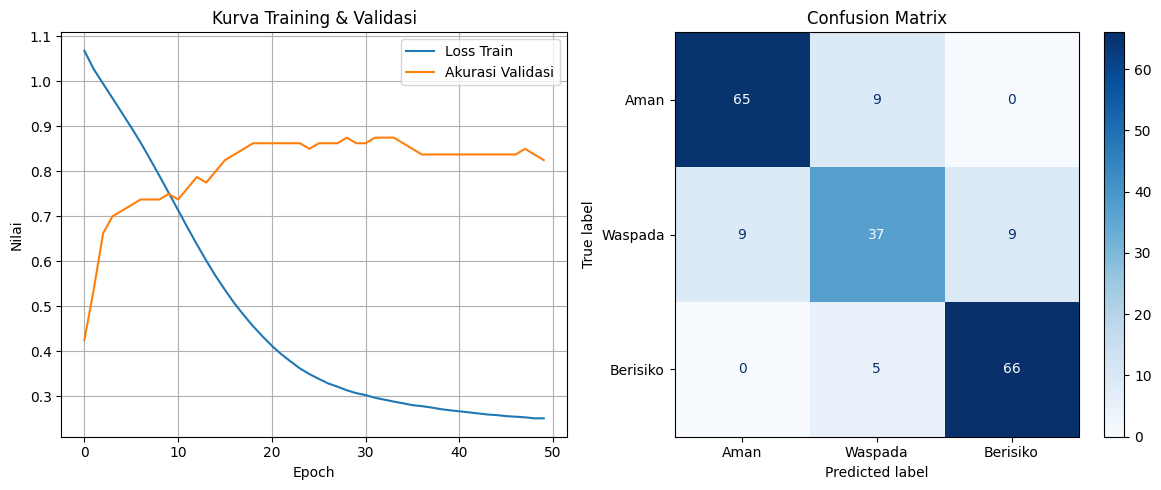

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# 1. Plot kurva training dan validasi
ax[0].plot(mlp.loss_curve_, label="Loss Train")
ax[0].plot(mlp.validation_scores_, label="Akurasi Validasi")
ax[0].set_title("Kurva Training & Validasi")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Nilai")
ax[0].legend()
ax[0].grid(True)

# 2. Plot Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABEL_TEKS)
disp.plot(ax=ax[1], cmap="Blues", values_format="d")
ax[1].set_title("Confusion Matrix")

plt.tight_layout()
plt.show()

### Langkah 7: Gerbang Evaluasi & Simpan Model

In [23]:
import json
import joblib
import sklearn
import pandas as pd
import numpy as np

TARGET_F1 = 0.80
if f1 >= TARGET_F1 and f1 > f1_base:
    joblib.dump(model, "model_status_akademik.pkl")
    info = {
        "nama_model": "DNN (MLPClassifier 64-32-16)",
        "fitur_numerik": FITUR_NUMERIK,
        "fitur_kategori": FITUR_KATEGORI,
        "kelas": [str(c) for c in le.classes_], # Menggunakan nama kelas asli bertipe string
        "rentang_fitur": {c: [float(df[c].min()), float(df[c].max())] for c in FITUR_NUMERIK},
        "metrik": {"accuracy": round(float(acc), 4), "f1_macro": round(float(f1), 4),
                   "f1_baseline": round(float(f1_base), 4), "n_test": int(len(y_test))},
        "versi": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__,
                  "numpy": np.__version__, "joblib": joblib.__version__},
    }
    with open("model_info.json", "w") as f:
        json.dump(info, f, indent=2)
    print("LOLOS evaluasi -> model_status_akademik.pkl & model_info.json disimpan")
else:
    print(f"BELUM LOLOS (F1 {f1:.4f} < {TARGET_F1}) -> perbaiki model, jangan deploy")

LOLOS evaluasi -> model_status_akademik.pkl & model_info.json disimpan


### Langkah 8: Uji Muat Ulang Model

In [25]:
import joblib
import pandas as pd

model = joblib.load("model_status_akademik.pkl")
contoh = pd.DataFrame([{
    "ipk": 3.45, "kehadiran": 92, "jam_belajar": 12,
    "tugas_terkumpul": 95, "nilai_uts": 82, "aktif_organisasi": "Ya",
}])

# Memprediksi kelas numerik dan mengonversinya kembali ke label string asli
pred_numerik = model.predict(contoh)[0]
pred_teks = le.inverse_transform([pred_numerik])[0]
print("Prediksi :", pred_teks)

proba = model.predict_proba(contoh)[0]
# Mengonversi model.classes_ (numerik) kembali ke nama kelas asli
classes_teks = le.inverse_transform(model.classes_)

for kelas, p in zip(classes_teks, proba):
    print(f"  {kelas:9s}: {p:.3f}")

Prediksi : Aman
  Aman     : 0.995
  Berisiko : 0.000
  Waspada  : 0.005


### Langkah 9: Unduh File (Khusus Colab)

In [26]:
from google.colab import files
files.download("model_status_akademik.pkl")
files.download("model_info.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>